# UPI Fraud Transaction Detection
End-to-end pipeline: data cleaning → EDA → feature engineering → modeling → evaluation → export for Power BI.

## 1. Imports

In [2]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   -- ------------------------------------- 3.7/48.9 MB 14.1 MB/s eta 0:00:04
   ------ --------------------------------- 8.1/48.9 MB 17.5 MB/s eta 0:00:03
   ---------- ----------------------------- 12.6/48.9 MB 19.2 MB/s eta 0:00:02
   ------------- -------------------------- 17.0/48.9 MB 19.7 MB/s eta 0:00:02
   ---------------- ----------------------- 20.4/48.9 MB 19.1 MB/s eta 0:00:02
   -------------------- ------------------- 24.6/48.9 MB 19.2 MB/s eta 0:00:02
   ----------------------- ---------------- 28.3/48.9 MB 18.8 MB/s eta 0:00:02
   -------------------------- ------------- 32.0/48.9 MB 18.6 MB/s eta 0:00:01
   ---------------------------- ----------- 35.1/48.9 MB 18.3 MB/s eta 0:00:01
   -------------------------------- ------- 39.3/48.9 MB 18.3 MB/s eta 0:00:01
   ------------------------------------ --- 44.6/48.9 MB 18.9 MB/s eta 0

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, precision_score, recall_score, f1_score
)

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
RANDOM_STATE = 42


## 2. Load & Inspect Data

In [4]:
df = pd.read_csv('upi_fraud_detection.csv')
df.head()

,transaction ID,timestamp,sender ID,receiver ID,amount,merchant category,transaction type,location,device type,UPI channel,hour of day,day of week,historical spend pattern,risk label,anomaly flag
0,TXN1000000,2025-02-02 14:30:00,S373034,R459071,161.82,Grocery,Recharge,Lucknow,Android,UPI ID,14,Sunday,121.48,Legitimate,0
1,TXN1000001,2025-10-10 08:08:00,S311773,R214769,248.17,P2P Transfer,Merchant Payment,Mumbai,iOS,UPI App,8,Friday,230.49,Legitimate,0
2,TXN1000002,2025-08-27 16:21:00,S216279,R874831,93.54,Healthcare,Merchant Payment,Delhi,iOS,UPI App,16,Wednesday,100.00,Legitimate,0
3,TXN1000003,2025-06-10 08:47:00,S539218,R795856,304.91,Shopping,Merchant Payment,Bengaluru,iOS,QR Code,8,Tuesday,224.10,Legitimate,0
4,TXN1000004,2025-06-08 06:36:00,S276890,R858477,382.30,P2P Transfer,Merchant Payment,Lucknow,Web,UPI App,6,Sunday,179.95,Legitimate,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   transaction ID            12000 non-null  object 
 1   timestamp                 12000 non-null  object 
 2   sender ID                 12000 non-null  object 
 3   receiver ID               12000 non-null  object 
 4   amount                    12000 non-null  float64
 5   merchant category         11982 non-null  object 
 6   transaction type          12000 non-null  object 
 7   location                  11988 non-null  object 
 8   device type               11985 non-null  object 
 9   UPI channel               12000 non-null  object 
 10  hour of day               12000 non-null  int64  
 11  day of week               12000 non-null  object 
 12  historical spend pattern  11980 non-null  float64
 13  risk label                12000 non-null  object 
 14  anomal

In [6]:
df.describe()

,amount,hour of day,historical spend pattern,anomaly flag
count,12000.000000,12000.000000,11980.000000,12000.000000
mean,356.279821,14.285333,403.430466,0.078333
std,517.344632,5.472895,627.828117,0.268707
min,20.000000,0.000000,100.000000,0.000000
25%,99.082500,10.000000,100.000000,0.000000
50%,202.540000,15.000000,204.400000,0.000000
75%,411.630000,19.000000,438.197500,0.000000
max,14651.810000,23.000000,13910.260000,1.000000


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11975 entries, 0 to 11974
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   transaction ID              11975 non-null  object        
 1   timestamp                   11975 non-null  datetime64[ns]
 2   sender ID                   11975 non-null  object        
 3   receiver ID                 11975 non-null  object        
 4   amount                      11975 non-null  float64       
 5   merchant category           11975 non-null  object        
 6   transaction type            11975 non-null  object        
 7   location                    11975 non-null  object        
 8   device type                 11975 non-null  object        
 9   UPI channel                 11975 non-null  object        
 10  hour of day                 11975 non-null  int64         
 11  day of week                 11975 non-null  object        


In [33]:
df.columns

Index(['transaction ID', 'timestamp', 'sender ID', 'receiver ID', 'amount',
       'merchant category', 'transaction type', 'location', 'device type',
       'UPI channel', 'hour of day', 'day of week', 'historical spend pattern',
       'risk label', 'anomaly flag', 'sender_transaction_count',
       'sender_total_amount', 'sender_average_amount', 'amount_deviation',
       'amount_to_historical_ratio', 'receiver_transaction_count',
       'night_transaction'],
      dtype='object')

In [7]:
df.isnull().sum()

transaction ID               0
timestamp                    0
sender ID                    0
receiver ID                  0
amount                       0
merchant category           18
transaction type             0
location                    12
device type                 15
UPI channel                  0
hour of day                  0
day of week                  0
historical spend pattern    20
risk label                   0
anomaly flag                 0
dtype: int64

In [8]:
print(df['risk label'].value_counts())
print('\nFraud rate: {:.2f}%'.format((df['risk label']=='Fraud').mean()*100))

risk label
Legitimate    11400
Fraud           600
Name: count, dtype: int64

Fraud rate: 5.00%


**Takeaway:** the dataset is heavily imbalanced (~5% fraud). This drives every modeling decision below — accuracy will be misleading, and the split/resampling steps must be done carefully.

## 3. Data Cleaning

In [9]:
# Fill missing values per-column instead of dropping rows wholesale —
# this keeps rows that only had one non-critical field missing.
df['merchant category'] = df['merchant category'].fillna('Unknown')
df['location'] = df['location'].fillna('Unknown')
df['device type'] = df['device type'].fillna('Unknown')
df['historical spend pattern'] = df['historical spend pattern'].fillna(
    df['historical spend pattern'].median()
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df.isnull().sum()


transaction ID              0
timestamp                   0
sender ID                   0
receiver ID                 0
amount                      0
merchant category           0
transaction type            0
location                    0
device type                 0
UPI channel                 0
hour of day                 0
day of week                 0
historical spend pattern    0
risk label                  0
anomaly flag                0
dtype: int64

In [10]:
# Duplicate check
print("Full duplicate rows:", df.duplicated().sum())
print("Duplicate transaction IDs:", df['transaction ID'].duplicated().sum())
df = df.drop_duplicates()


Full duplicate rows: 25
Duplicate transaction IDs: 25


In [11]:
# Sanity checks
print("Invalid (<=0) amounts:", (df['amount'] <= 0).sum())
print("\nRisk label counts:\n", df['risk label'].value_counts())
print("\nAnomaly flag counts:\n", df['anomaly flag'].value_counts())


Invalid (<=0) amounts: 0

Risk label counts:
 risk label
Legitimate    11377
Fraud           598
Name: count, dtype: int64

Anomaly flag counts:
 anomaly flag
0    11037
1      938
Name: count, dtype: int64


## 4. Exploratory Data Analysis

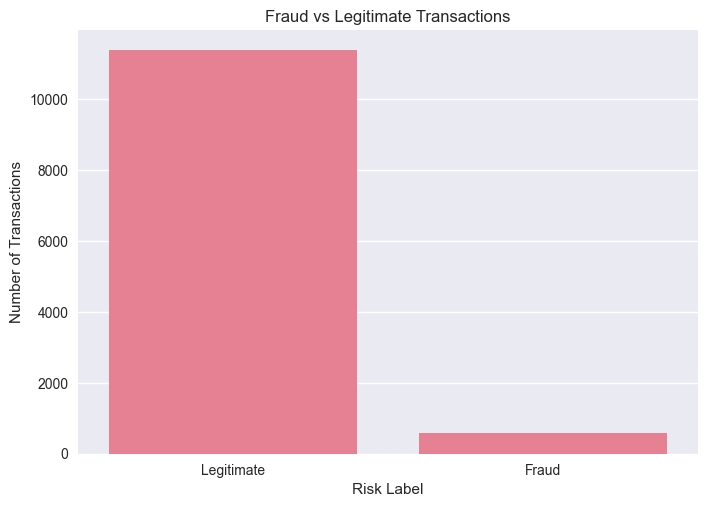

In [12]:
sns.countplot(data=df, x='risk label')
plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Risk Label"); plt.ylabel("Number of Transactions")
plt.show()


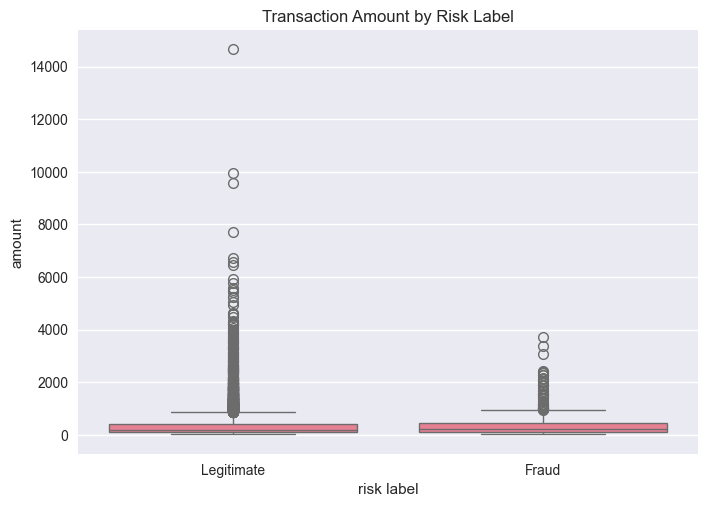

In [13]:
sns.boxplot(data=df, x="risk label", y="amount")
plt.title("Transaction Amount by Risk Label")
plt.show()


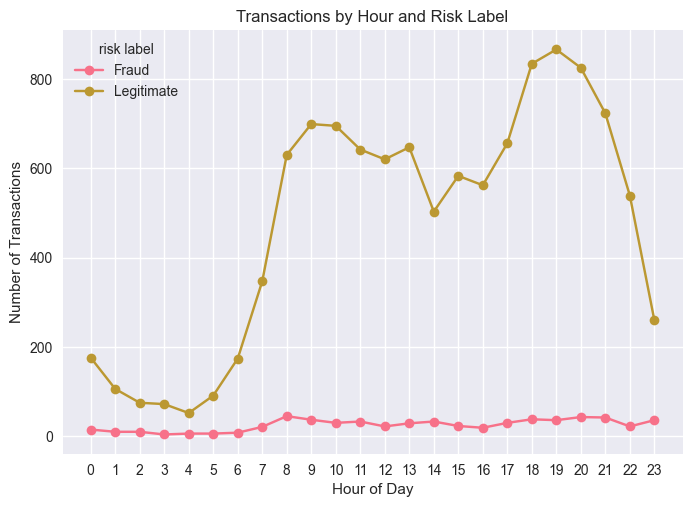

In [14]:
hour_fraud = df.groupby("hour of day")["risk label"].value_counts().unstack(fill_value=0)
hour_fraud.plot(kind="line", marker="o")
plt.title("Transactions by Hour and Risk Label")
plt.xlabel("Hour of Day"); plt.ylabel("Number of Transactions")
plt.xticks(range(0, 24))
plt.show()


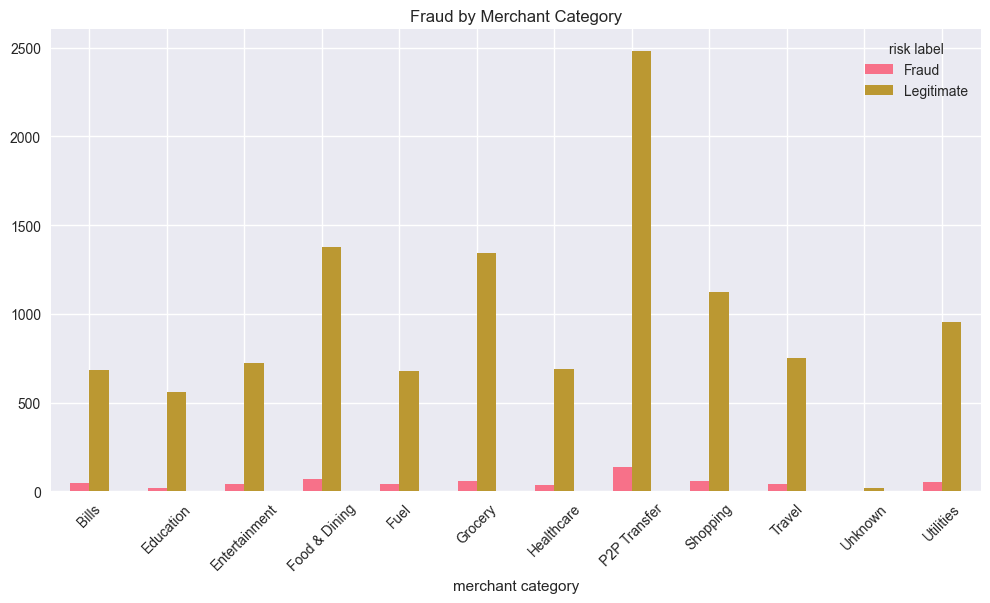

In [15]:
merchant_fraud = pd.crosstab(df["merchant category"], df["risk label"])
merchant_fraud.plot(kind="bar", figsize=(12, 6))
plt.title("Fraud by Merchant Category")
plt.xticks(rotation=45)
plt.show()


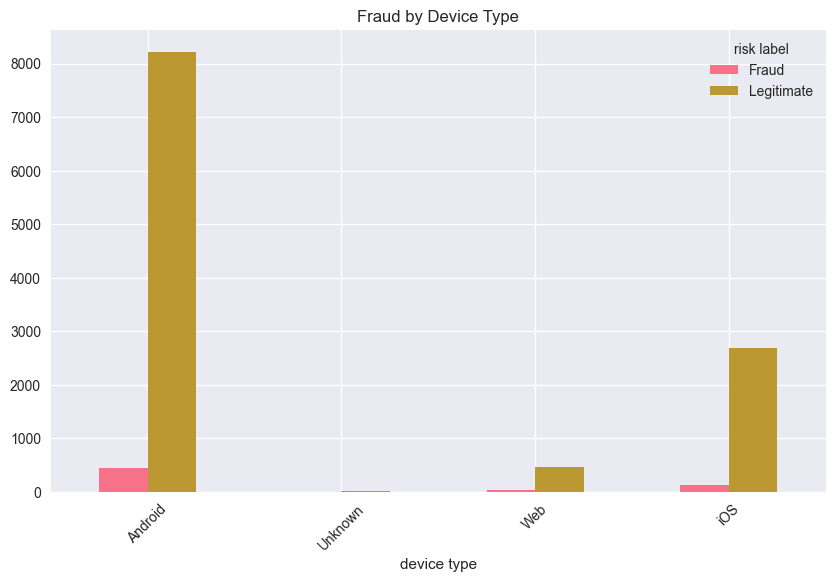

In [16]:
device_fraud = pd.crosstab(df['device type'], df['risk label'])
device_fraud.plot(kind="bar", figsize=(10, 6))
plt.title("Fraud by Device Type")
plt.xticks(rotation=45)
plt.show()


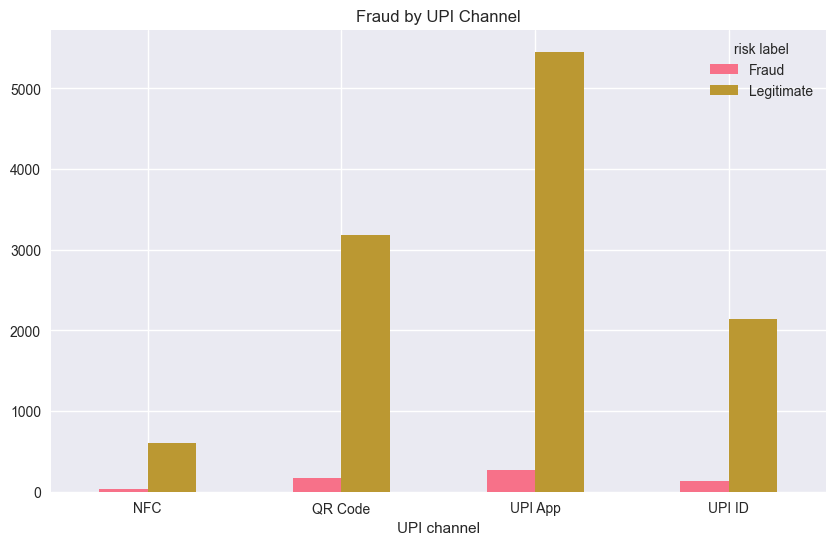

In [17]:
channel_fraud = pd.crosstab(df['UPI channel'], df['risk label'])
channel_fraud.plot(kind="bar", figsize=(10, 6))
plt.title("Fraud by UPI Channel")
plt.xticks(rotation=0)
plt.show()


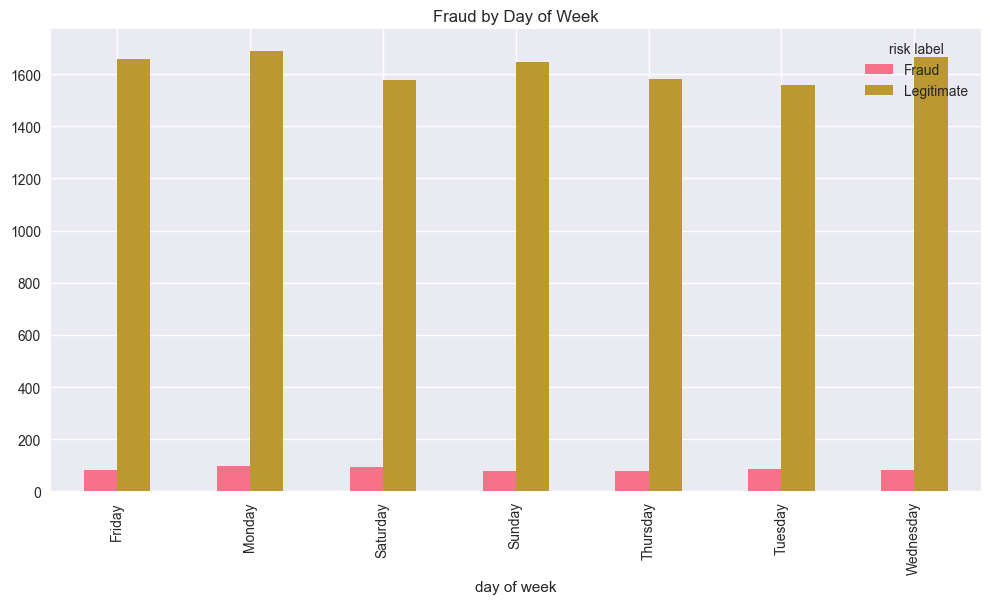

In [18]:
day_fraud = pd.crosstab(df['day of week'], df['risk label'])
day_fraud.plot(kind="bar", figsize=(12, 6))
plt.title("Fraud by Day of Week")
plt.show()


risk label    Fraud  Legitimate
anomaly flag                   
0               529       10508
1                69         869


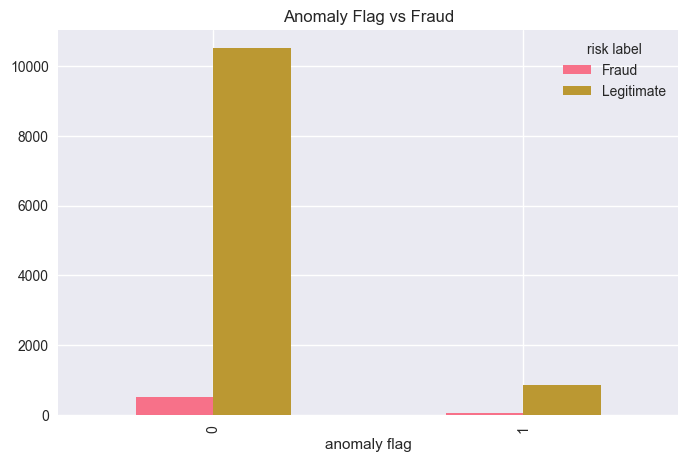

In [19]:
anomaly_fraud = pd.crosstab(df["anomaly flag"], df["risk label"])
print(anomaly_fraud)
anomaly_fraud.plot(kind="bar", figsize=(8, 5))
plt.title("Anomaly Flag vs Fraud")
plt.show()


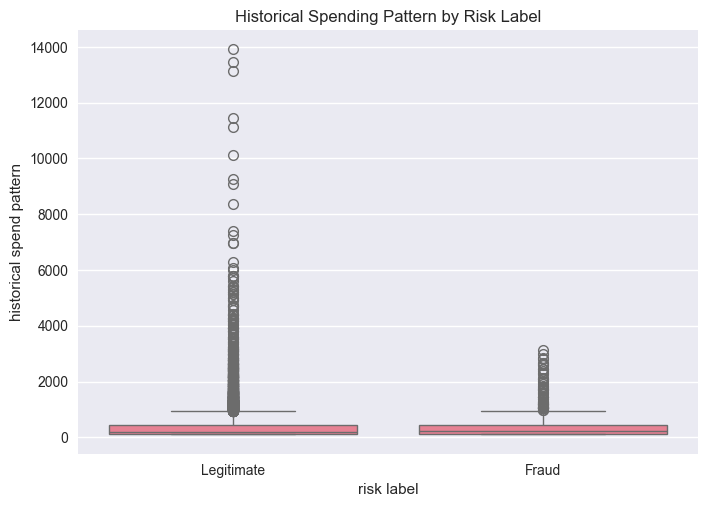

In [20]:
sns.boxplot(data=df, x="risk label", y="historical spend pattern")
plt.title("Historical Spending Pattern by Risk Label")
plt.show()


**EDA takeaway:** fraud rates are fairly flat across single categorical columns (no single feature is a strong standalone predictor) — real signal, if present, will come from combining features. Confirm this quantitatively next.

## 5. Feature Engineering

In [21]:
df['sender_transaction_count'] = df.groupby('sender ID')['transaction ID'].transform('count')
df['sender_total_amount'] = df.groupby('sender ID')['amount'].transform('sum')
df['sender_average_amount'] = df.groupby('sender ID')['amount'].transform('mean')
df['amount_deviation'] = df['amount'] - df['sender_average_amount']
df['amount_to_historical_ratio'] = df['amount'] / df['historical spend pattern'].replace(0, 1)
df['receiver_transaction_count'] = df.groupby('receiver ID')['transaction ID'].transform('count')
df['night_transaction'] = df['hour of day'].apply(lambda h: 1 if 0 <= h <= 5 else 0)
df.head()


,transaction ID,timestamp,sender ID,receiver ID,amount,merchant category,transaction type,location,device type,UPI channel,...,historical spend pattern,risk label,anomaly flag,sender_transaction_count,sender_total_amount,sender_average_amount,amount_deviation,amount_to_historical_ratio,receiver_transaction_count,night_transaction
0,TXN1000000,2025-02-02 14:30:00,S373034,R459071,161.82,Grocery,Recharge,Lucknow,Android,UPI ID,...,121.48,Legitimate,0,1,161.82,161.82,0.0,1.332071,1,0
1,TXN1000001,2025-10-10 08:08:00,S311773,R214769,248.17,P2P Transfer,Merchant Payment,Mumbai,iOS,UPI App,...,230.49,Legitimate,0,1,248.17,248.17,0.0,1.076706,1,0
2,TXN1000002,2025-08-27 16:21:00,S216279,R874831,93.54,Healthcare,Merchant Payment,Delhi,iOS,UPI App,...,100.00,Legitimate,0,1,93.54,93.54,0.0,0.935400,1,0
3,TXN1000003,2025-06-10 08:47:00,S539218,R795856,304.91,Shopping,Merchant Payment,Bengaluru,iOS,QR Code,...,224.10,Legitimate,0,1,304.91,304.91,0.0,1.360598,1,0
4,TXN1000004,2025-06-08 06:36:00,S276890,R858477,382.30,P2P Transfer,Merchant Payment,Lucknow,Web,UPI App,...,179.95,Legitimate,0,1,382.30,382.30,0.0,2.124479,1,0


## 6. Signal Check (before committing to a model)

In [22]:
numerical_features = [
    "amount", "hour of day", "historical spend pattern", "anomaly flag",
    "sender_transaction_count", "sender_total_amount", "sender_average_amount",
    "amount_deviation", "amount_to_historical_ratio",
    "receiver_transaction_count", "night_transaction"
]
y_check = (df["risk label"] == "Fraud").astype(int)
mi_scores = mutual_info_classif(df[numerical_features].fillna(0), y_check, random_state=RANDOM_STATE)
pd.Series(mi_scores, index=numerical_features).sort_values(ascending=False)


receiver_transaction_count    0.007136
hour of day                   0.003073
sender_transaction_count      0.001839
night_transaction             0.000812
amount_deviation              0.000613
sender_average_amount         0.000600
historical spend pattern      0.000473
amount                        0.000430
anomaly flag                  0.000000
sender_total_amount           0.000000
amount_to_historical_ratio    0.000000
dtype: float64

**Rule of thumb:** scores near 0 mean almost no relationship with fraud; higher scores (~0.02+) indicate a feature worth keeping in the model. If everything here is near-zero, expect modest model performance regardless of which algorithm you choose — that's a data limitation, not a modeling mistake.

## 7. Feature Selection, Train/Test Split, Encoding

In [23]:
categorical_features = [
    "merchant category", "transaction type", "location",
    "device type", "UPI channel", "day of week"
]

features = categorical_features + numerical_features

X = df[features]
y = df["risk label"].map({"Legitimate": 0, "Fraud": 1})

print(y.value_counts())


risk label
0    11377
1      598
Name: count, dtype: int64


In [24]:
# Split BEFORE encoding — the encoder must never see the test set during fit
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)   # fit + transform
X_test_processed = preprocessor.transform(X_test)          # transform ONLY

print("Train shape:", X_train_processed.shape)
print("Test shape :", X_test_processed.shape)
print(f"Train fraud rate: {y_train.mean()*100:.2f}%  |  Test fraud rate: {y_test.mean()*100:.2f}%")


Train shape: (9580, 55)
Test shape : (2395, 55)
Train fraud rate: 4.99%  |  Test fraud rate: 5.01%


## 8. Train & Compare Models
Baseline (Logistic Regression) first, then two stronger models, so we can see whether the extra complexity is actually earning its keep.

In [25]:
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
log_reg.fit(X_train_processed, y_train)

rf = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"
)
rf.fit(X_train_processed, y_train)

xgb = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    eval_metric="logloss", random_state=RANDOM_STATE
)
xgb.fit(X_train_processed, y_train)

models = {"Logistic Regression": log_reg, "Random Forest": rf, "XGBoost": xgb}


C:\Users\vikra\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 9. Evaluate — Precision/Recall/F1/ROC-AUC/PR-AUC (not just accuracy)

In [26]:
summary_rows = []
probas = {}

for name, m in models.items():
    pred = m.predict(X_test_processed)
    proba = m.predict_proba(X_test_processed)[:, 1]
    probas[name] = proba

    summary_rows.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba)
    })

summary_df = pd.DataFrame(summary_rows).set_index("Model").round(4)
summary_df


C:\Users\vikra\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,
Logistic Regression,0.0545,0.4417,0.0971,0.5447,0.0572
Random Forest,0.0000,0.0000,0.0000,0.5566,0.0607
XGBoost,0.0000,0.0000,0.0000,0.5540,0.0696


Best model by PR-AUC: XGBoost

              precision    recall  f1-score   support

  Legitimate       0.95      1.00      0.97      2275
       Fraud       0.00      0.00      0.00       120

    accuracy                           0.95      2395
   macro avg       0.47      0.50      0.49      2395
weighted avg       0.90      0.95      0.93      2395



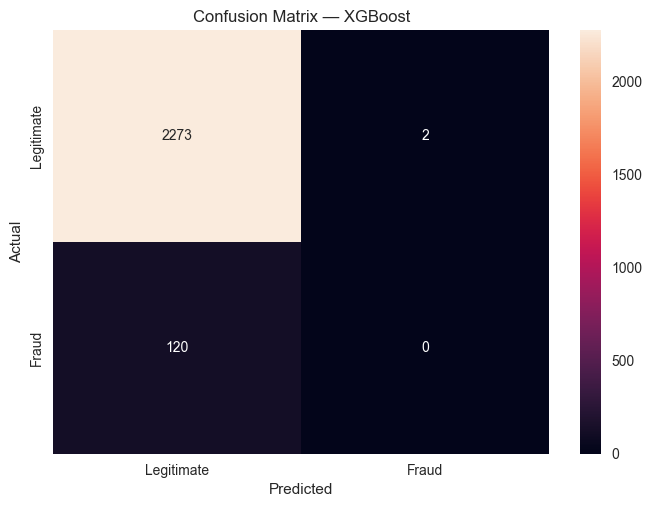

In [27]:
# Detailed report + confusion matrix for the best model (adjust name if needed)
best_name = summary_df["PR-AUC"].idxmax()
best_model = models[best_name]
y_pred_best = best_model.predict(X_test_processed)

print(f"Best model by PR-AUC: {best_name}\n")
print(classification_report(y_test, y_pred_best, target_names=["Legitimate", "Fraud"]))

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Legitimate","Fraud"], yticklabels=["Legitimate","Fraud"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_name}")
plt.show()


## 10. Feature Importance

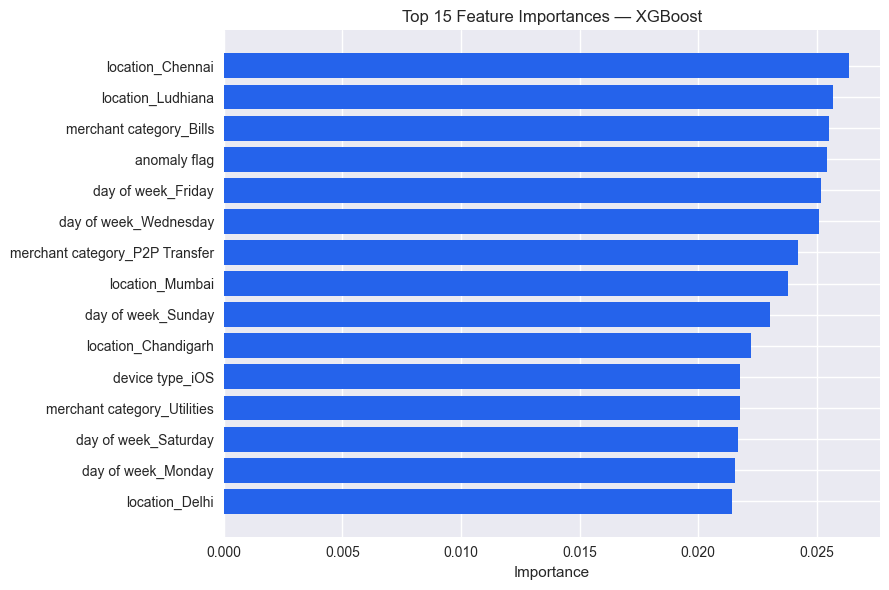

In [28]:
if hasattr(best_model, "feature_importances_"):
    feature_names = (
        list(preprocessor.named_transformers_["categorical"].get_feature_names_out(categorical_features))
        + numerical_features
    )
    importances = pd.DataFrame({
        "feature": feature_names,
        "importance": best_model.feature_importances_
    }).sort_values("importance", ascending=False).head(15)

    plt.figure(figsize=(9, 6))
    plt.barh(importances["feature"][::-1], importances["importance"][::-1], color="#2563eb")
    plt.xlabel("Importance")
    plt.title(f"Top 15 Feature Importances — {best_name}")
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_name} has no feature_importances_ attribute (use .coef_ for Logistic Regression instead).")


## 11. Threshold Tuning
The default 0.5 probability cutoff is rarely optimal for imbalanced fraud data — lowering it trades precision for recall (catches more fraud, more false alarms).

In [29]:
best_proba = probas[best_name]

for threshold in [0.5, 0.25, 0.20, 0.15, 0.10, 0.05]:
    preds = (best_proba >= threshold).astype(int)
    print(f"Threshold {threshold:.2f} | Flagged: {preds.sum():4d} | "
          f"Precision: {precision_score(y_test, preds, zero_division=0):.3f} | "
          f"Recall: {recall_score(y_test, preds, zero_division=0):.3f} | "
          f"F1: {f1_score(y_test, preds, zero_division=0):.3f}")


Threshold 0.50 | Flagged:    2 | Precision: 0.000 | Recall: 0.000 | F1: 0.000
Threshold 0.25 | Flagged:   19 | Precision: 0.158 | Recall: 0.025 | F1: 0.043
Threshold 0.20 | Flagged:   42 | Precision: 0.095 | Recall: 0.033 | F1: 0.049
Threshold 0.15 | Flagged:   78 | Precision: 0.077 | Recall: 0.050 | F1: 0.061
Threshold 0.10 | Flagged:  192 | Precision: 0.078 | Recall: 0.125 | F1: 0.096
Threshold 0.05 | Flagged:  667 | Precision: 0.060 | Recall: 0.333 | F1: 0.102


**Pick a threshold based on business cost**: if missing fraud is far costlier than a false alarm, favor higher recall (lower threshold); if false alarms annoy customers and cost investigation time, favor higher precision (higher threshold).

## 12. Export for Power BI

In [30]:
results = X_test.copy()
results["actual_label"] = y_test.values
results["predicted_label"] = y_pred_best
results["predicted_probability"] = best_proba
results.to_csv("predictions_for_powerbi.csv", index=False)

pd.DataFrame(
    cm, index=["Actual_Legit", "Actual_Fraud"], columns=["Pred_Legit", "Pred_Fraud"]
).to_csv("confusion_matrix.csv")

if hasattr(best_model, "feature_importances_"):
    importances.to_csv("feature_importance.csv", index=False)

summary_df.to_csv("model_comparison.csv")

print("Exported: predictions_for_powerbi.csv, confusion_matrix.csv, feature_importance.csv, model_comparison.csv")


Exported: predictions_for_powerbi.csv, confusion_matrix.csv, feature_importance.csv, model_comparison.csv


## 13. Summary
- Checked for missing values and cleaned selectively (no unnecessary row loss)
- Verified class imbalance (~5% fraud) upfront — drove split/metric/resampling choices
- Ran a signal check (mutual information) before modeling
- Compared 3 models on Precision/Recall/F1/ROC-AUC/PR-AUC, not just accuracy
- Inspected feature importance to validate the engineered features
- Tuned the decision threshold instead of defaulting to 0.5
- Exported clean CSVs for the Power BI report